In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sys
sys.path.append('/media/dll-1/SSD 4TB/code/REEDNet/')  # Replace with real path
from EEGDataLoader import EEGDataset
from models.REEDNetModel import REEDNetModel
import config


model_saving_name = "/media/dll-1/SSD 4TB/EEG Datasets/experiment/nouman_conv_2/model/weights/conv_tt_012.pt"

epochs = 50
batch_size = 64
hidden_size = 20
output_size = 3  # Binary classification
number_of_eeg_channels = 1
eval_batch = 1
threshold = 0.495
active_branches = [0,1,2]

/home/anaconda/anaconda3/envs/braindecode/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
train_dataset = EEGDataset(config.train_data_csv, number_of_eeg_channels=number_of_eeg_channels)
val_dataset = EEGDataset(config.val_data_csv, number_of_eeg_channels=number_of_eeg_channels)
test_dataset = EEGDataset(config.test_data_csv, number_of_eeg_channels=number_of_eeg_channels)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)#, collate_fn=collate)
val_loader = DataLoader(val_dataset, batch_size=eval_batch, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=eval_batch, shuffle=False)

In [ ]:
input = train_dataset.__getitem__(0)
input_x1 = input[1].shape
input_x2 = input[2].shape
input_x3 = input[3].shape
criterion = nn.CrossEntropyLoss()

loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

print(input_x1,input_x2,input_x3)
input_channels_list = [input_x1[1], input_x2[1], input_x3[1]]

model = REEDNetModel(input_channels_list=input_channels_list, output_size=3)

main_output, aux_outputs = model([input[1], input[2], input[3]], active_branch_indices=active_branches)
print("Output shape:", main_output.shape) 

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001,betas=(0.9, 0.98), eps=1e-9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

torch.Size([1, 1, 400]) torch.Size([1, 33, 14]) torch.Size([1, 30, 400])
Output shape: torch.Size([1, 3])


/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


ConvParallelEEG1DModel(
  (branches): ModuleList(
    (0): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(in_features=32, out_features=3, bias=True)
    )
    (1): ConvBranch1D(
      (conv): Sequential(
        (0): Conv1d(33, 32, kernel_size=(3,), stride=(1,), padding=(1,))
        (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (4): Dropout(p=0.3, inplace=False)
      )
      (global_pool): AdaptiveAvgPool1d(output_size=1)
      (linear): Linear(

In [14]:
# prev_eval_loss = 0
# prev_eval_acc = 0


In [15]:
# model = model.to(device)

# prev_eval_loss, prev_eval_acc = eval(model, val_loader, loss_fn, 1,False,'', active_branches, device)
# print("Loss:",prev_eval_loss, "Accuracy",prev_eval_acc)

In [16]:
# result = {"epoch":[],"train_loss":[],"train_acc":[],"eval_loss":[],"eval_acc":[],"test_acc":[],"test_loss":[]}
# saved_epoch = 0

In [17]:
# for epoch in range(epochs):  # loop over the dataset multiple times
#     train_loss, train_acc = train(model, train_loader,optimizer, loss_fn, active_branches, device)
#     print(f"Train Loss after epoch {epoch+2}: {train_loss} Train ACC after epoch {epoch}: {train_acc}")
#     eval_loss, eval_acc = eval(model, test_loader, loss_fn, eval_batch,False,'', active_branches, device)
#     print(f"VAL Loss after epoch {epoch}: {eval_loss} VAL ACC after epoch {epoch}: {eval_acc}")
#     # test_loss, test_acc = eval(model, test_loader, loss_fn, eval_batch,False,'', active_branches, device)
#     test_loss = eval_loss
#     test_acc = eval_acc
#     print(f"Test Loss after epoch {epoch}: {test_loss} Test Acc after epoch {epoch}: {test_acc}")

#     scheduler.step(eval_loss)
    
#     result['epoch'].append(epoch)
    
#     result['train_loss'].append(train_loss)
#     result['train_acc'].append(train_acc)
#     result['eval_loss'].append(eval_loss)
#     result['eval_acc'].append(eval_acc)
#     result['test_loss'].append(test_loss)
#     result['test_acc'].append(test_acc)

#     if prev_eval_acc < eval_acc:
#       prev_eval_acc = eval_acc
#       saved_epoch = epoch
#       torch.save(model.state_dict(), model_saving_name)
#       print("WEIGHTS SAVED")

In [18]:
# print("Epoch | Train Loss | Train Acc | Eval Loss | Eval Acc | Test Loss | Test Acc  ")
# for epoch in range(epochs):
#     if(saved_epoch == epoch):
#         print("Saved Weights")
#     print(result['epoch'][epoch],"|",result['train_loss'][epoch],"|",result['train_acc'][epoch],"|",result['eval_loss'][epoch],"|",result['eval_acc'][epoch],"|",result['test_loss'][epoch],"|",result['test_acc'][epoch])

In [10]:
model_state_dict = torch.load(model_saving_name)
# Load the state_dict into the model
model.load_state_dict(model_state_dict)
# test_loss, test_acc = eval(model, test_loader, loss_fn, eval_batch,True,prediction_saving_csv_eval, active_branches, device)
# print(f"Test Loss: {test_loss} Test ACC: {test_acc}")

# eval_loss, eval_acc = eval(model, train_loader, loss_fn, eval_batch,True,prediction_saving_csv_train)
# print(f"Train Loss: {eval_loss} Train ACC: {eval_acc}")

/tmp/ipykernel_108407/1353473940.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_state_dict = torch.load(model_saving_name)


<All keys matched successfully>


Running model on a subset of test data to collect features for t-SNE...


  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)



Collected features from 74774 samples.

Running t-SNE for: Raw EEG Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: FFT Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Wavelet Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Final Fused Features...
(74774, 96)
(74774,)
t-SNE calculation complete.


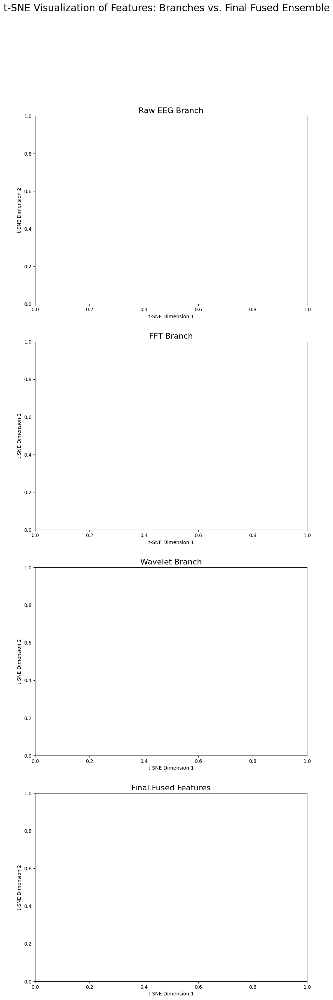

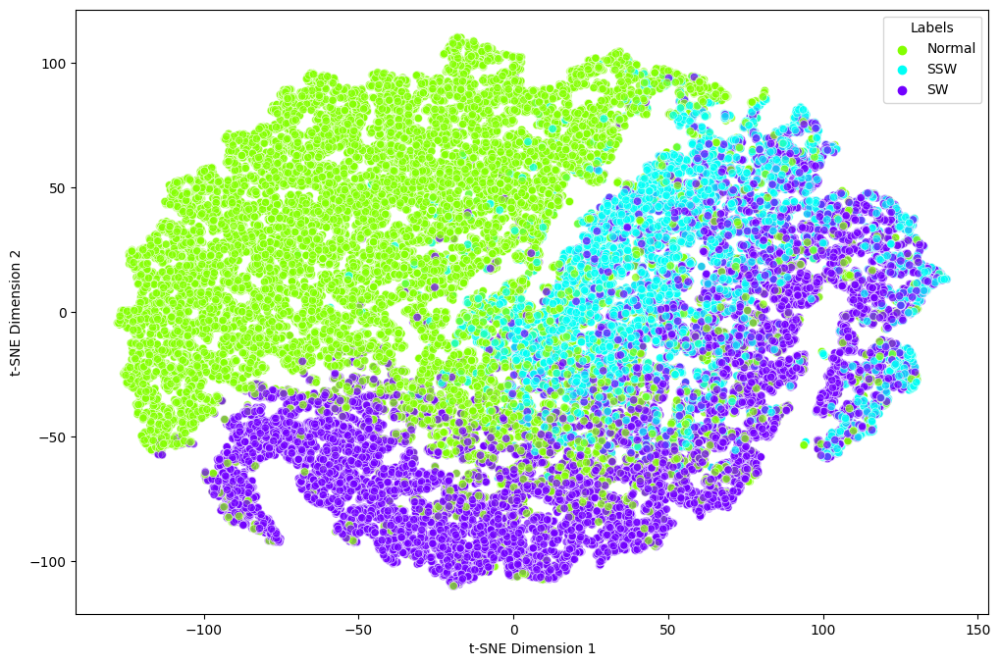

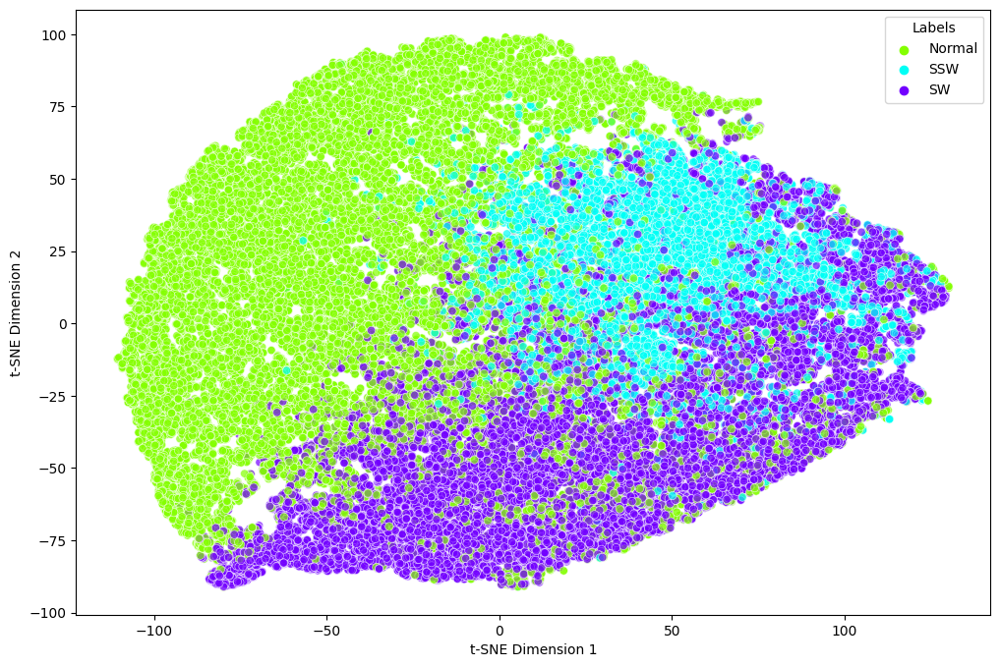

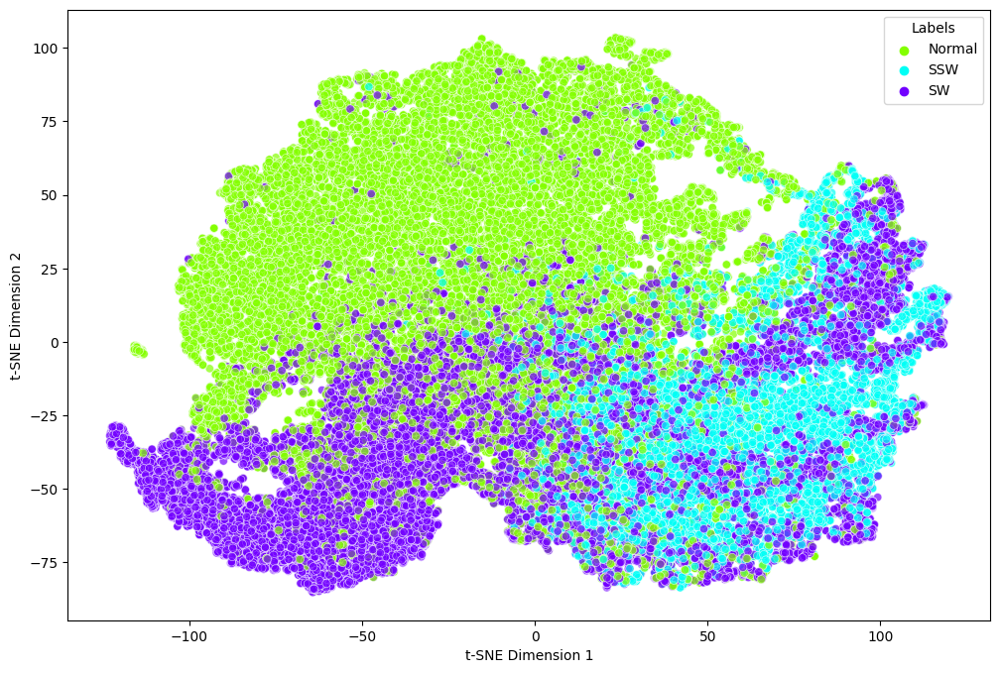

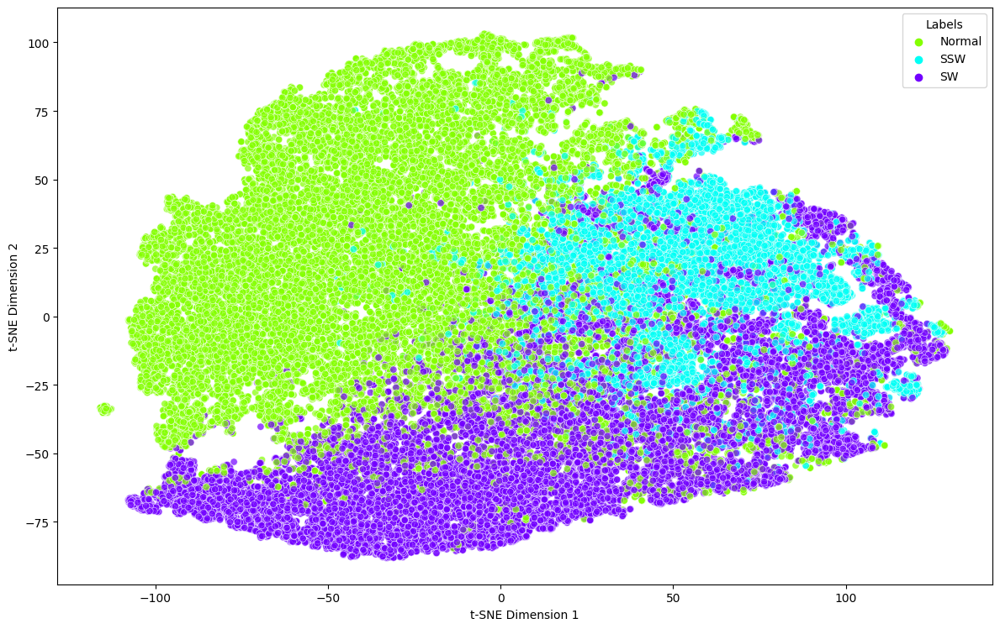

In [ ]:
# ====================================================================
# BLOCK 1: t-SNE VISUALIZATION (ALL BRANCHES + FUSED FEATURES)
# ====================================================================
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import collections
from tqdm import tqdm

# --- Step 1: Set up hooks to capture features from all sources ---
features = collections.defaultdict(list)

def create_branch_hook(key_name):
    def hook_fn(module, input, output):
        features[key_name].append(output[0].cpu().detach().numpy())
    return hook_fn

def get_fused_features_hook(module, input, output):
    features['fused_features'].append(input[0].cpu().detach().numpy())

# --- Step 2: Run a subset of data through the model to collect features ---
# try:
print("\nRunning model on a subset of test data to collect features for t-SNE...")

# Register four hooks on their respective modules
hook_handle_raw = model.branches[0].register_forward_hook(create_branch_hook('raw_features'))
hook_handle_fft = model.branches[1].register_forward_hook(create_branch_hook('fft_features'))
hook_handle_wavelet = model.branches[2].register_forward_hook(create_branch_hook('wavelet_features'))
hook_handle_fused = model.classifier.register_forward_hook(get_fused_features_hook)

true_labels = []
samples_collected = 0

model.eval()
with torch.no_grad():
    for _, eeg_data, fft_data, wavelet_data, labels in tqdm(test_loader, desc="Collecting Features"):
        model_inputs = [
            eeg_data.squeeze(1).to(device),
            fft_data.squeeze(1).to(device),
            wavelet_data.squeeze(1).to(device)
        ]
        
        _ = model(model_inputs, active_branch_indices=active_branches)
        
        true_labels.extend(labels.cpu().numpy())
        samples_collected += eeg_data.size(0)

# CRITICAL: Remove all hooks after use
hook_handle_raw.remove()
hook_handle_fft.remove()
hook_handle_wavelet.remove()
hook_handle_fused.remove()
print(f"\nCollected features from {samples_collected} samples.")

# --- Step 3: Run t-SNE and Visualize for all four feature sets ---
fig, axs = plt.subplots(4, 1, figsize=(10, 32))
fig.suptitle('t-SNE Visualization of Features: Branches vs. Final Fused Ensemble', fontsize=20)

feature_keys = ['raw_features', 'fft_features', 'wavelet_features', 'fused_features']
plot_titles = ['Raw EEG Branch', 'FFT Branch', 'Wavelet Branch', 'Final Fused Features']



# except NameError as e:
#      print(f"\nSkipping t-SNE analysis because a required variable was not found: {e}")
# except Exception as e:
    # print(f"\nAn error occurred during t-SNE analysis: {e}")


Running t-SNE for: Raw EEG Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: FFT Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Wavelet Branch...
(74774, 32)
(74774,)
t-SNE calculation complete.

Running t-SNE for: Final Fused Features...
(74774, 96)
(74774,)
t-SNE calculation complete.


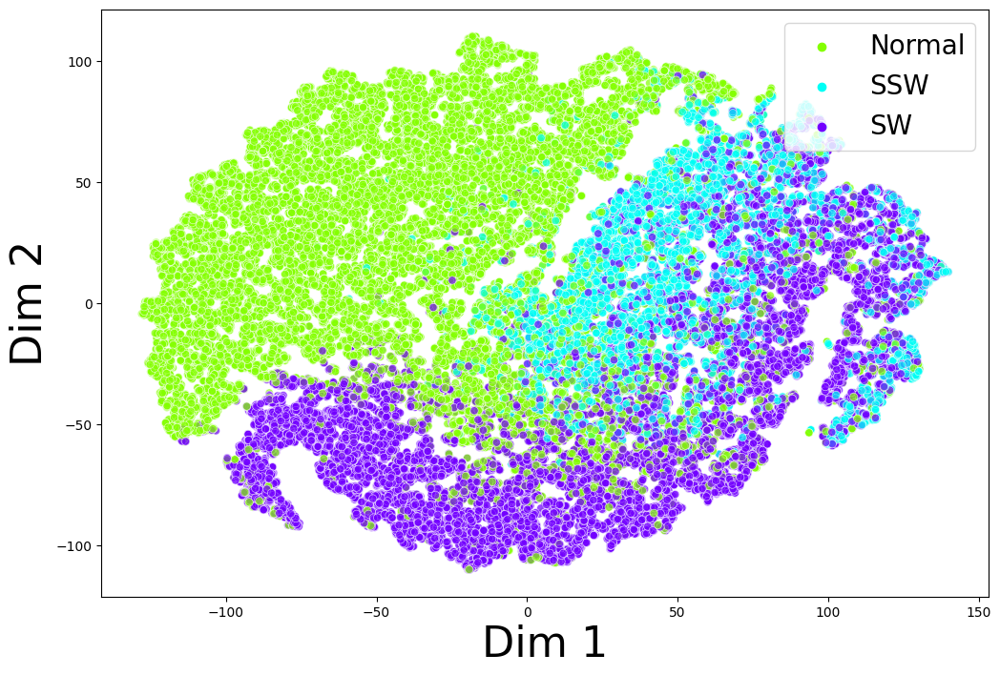

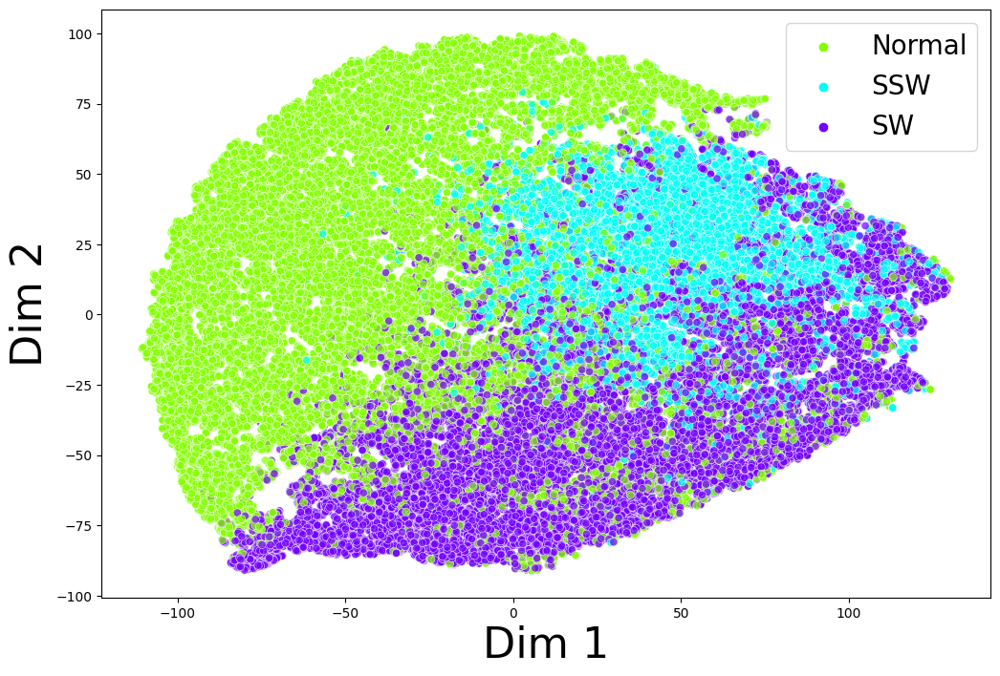

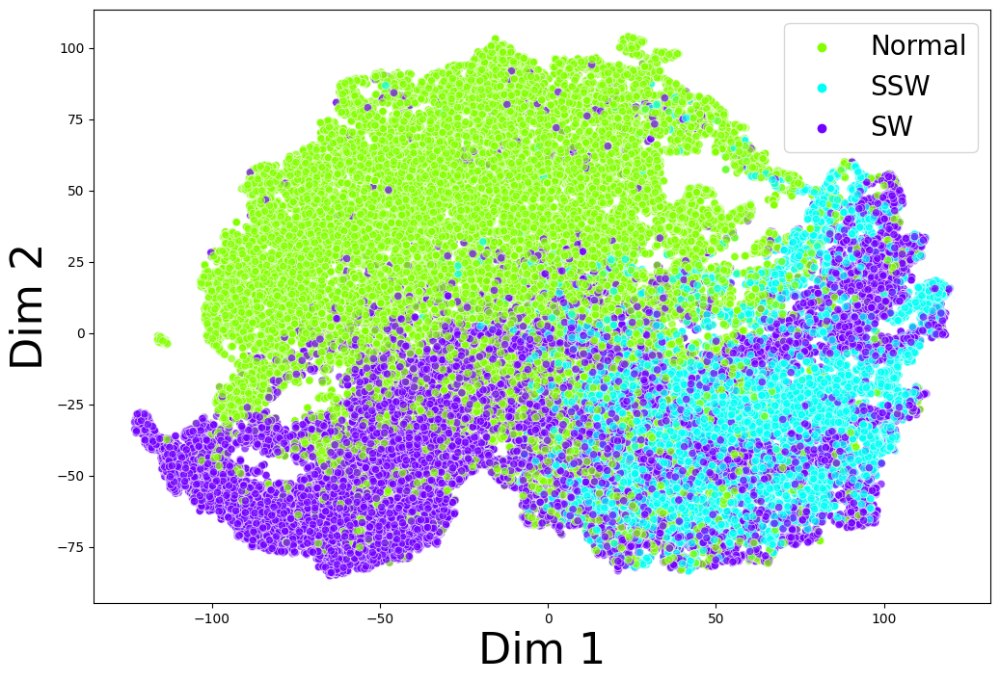

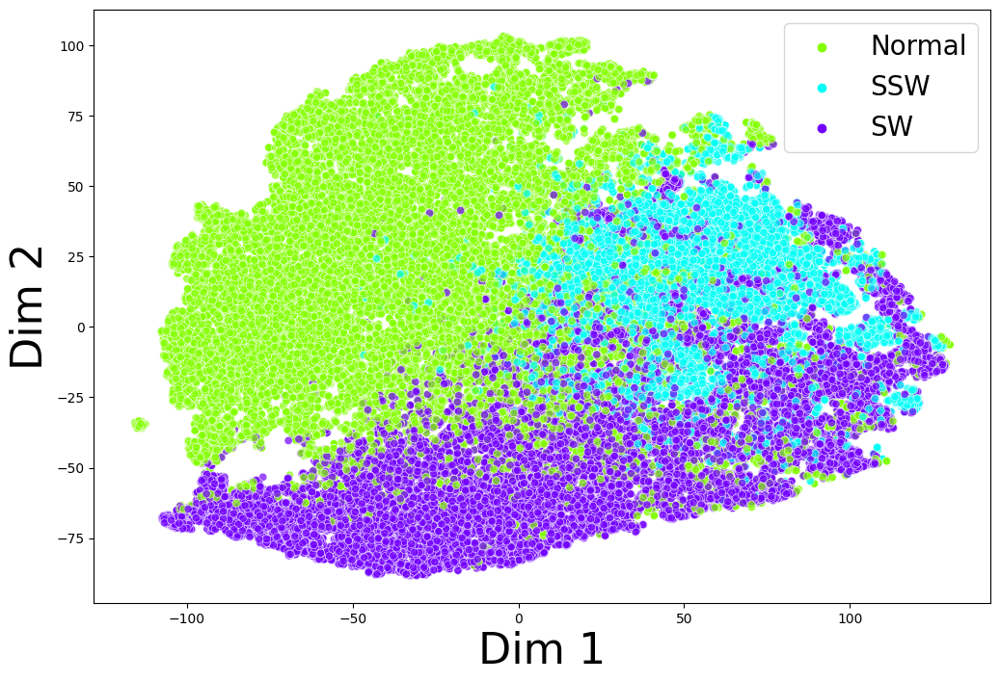

In [14]:
for ax, key, title in zip(axs, feature_keys, plot_titles):
    print(f"\nRunning t-SNE for: {title}...")
    
    features_np = np.concatenate(features[key], axis=0)
    # true_labels_np = np.array(true_labels)[:features_np.shape[0]]
    # true_labels_np = np.array(true_labels)[:features_np.shape[0]]
    true_labels_np = np.array(true_labels)
    # true_labels_np = np.repeat(true_labels, 7)
    print(features_np.shape)
    print(true_labels_np.shape)

    
    tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, learning_rate='auto', init='pca')
    tsne_results = tsne.fit_transform(features_np)
    print("t-SNE calculation complete.")

    label_map = {
    0: 'Normal',
    1: 'SSW',  # Sharp and Spike Wave
    2: 'SW'    # Slow Wave
    }
        

    true_labels_mapped = [label_map[label] for label in true_labels_np]

    tsne_df = pd.DataFrame({
        't-SNE Dimension 1': tsne_results[:,0],
        't-SNE Dimension 2': tsne_results[:,1],
        'Labels': true_labels_mapped 
    })

    plt.figure(figsize=(12, 8))
        
    sns.scatterplot(
        x="t-SNE Dimension 1", y="t-SNE Dimension 2",
        hue="Labels", 
        hue_order=['Normal', 'SSW', 'SW'], 
        palette=sns.color_palette("hsv", n_colors=len(label_map)), 
        data=tsne_df,
        legend="full",
        alpha=0.7
    )
    plt.xlabel('Dim 1', fontsize=32)
    plt.ylabel('Dim 2', fontsize=32)

    plt.legend(fontsize=20, title=None, loc='upper right')

# plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


--- Starting Captum Analysis for 4 Samples ---

--- Analyzing Sample #1 (Index: 0) ---
True Label: 0 | Model Prediction: 1


/media/dll-1/SSD 4TB/code/eeg_classifiers/EEDDataLoader.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  wavelet_transform = torch.tensor(coefficients_cmor, dtype=torch.float32)


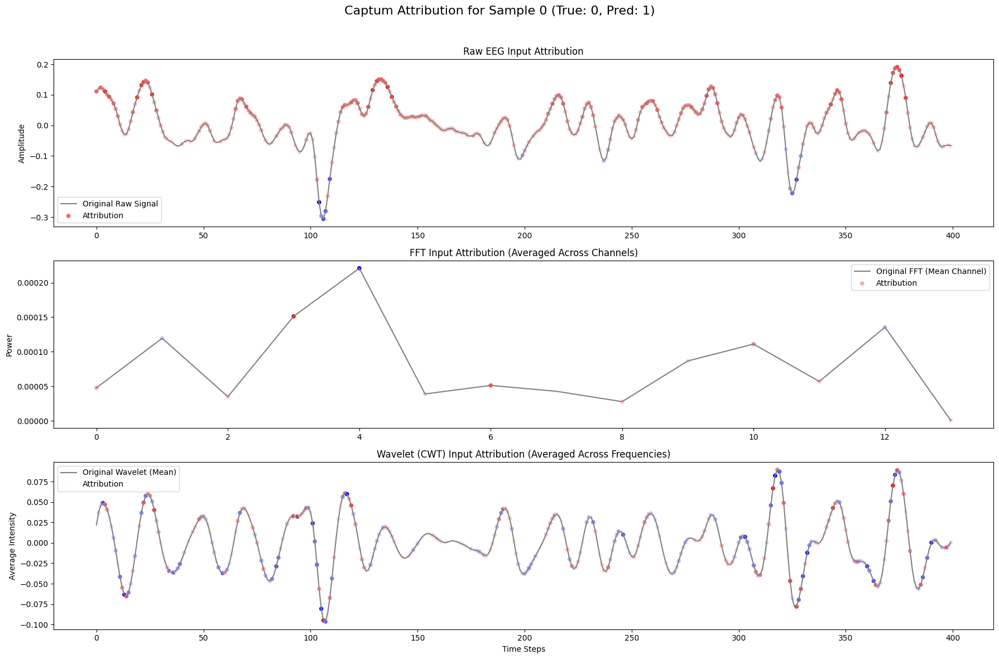


--- Analyzing Sample #2 (Index: 10) ---
True Label: 1 | Model Prediction: 1


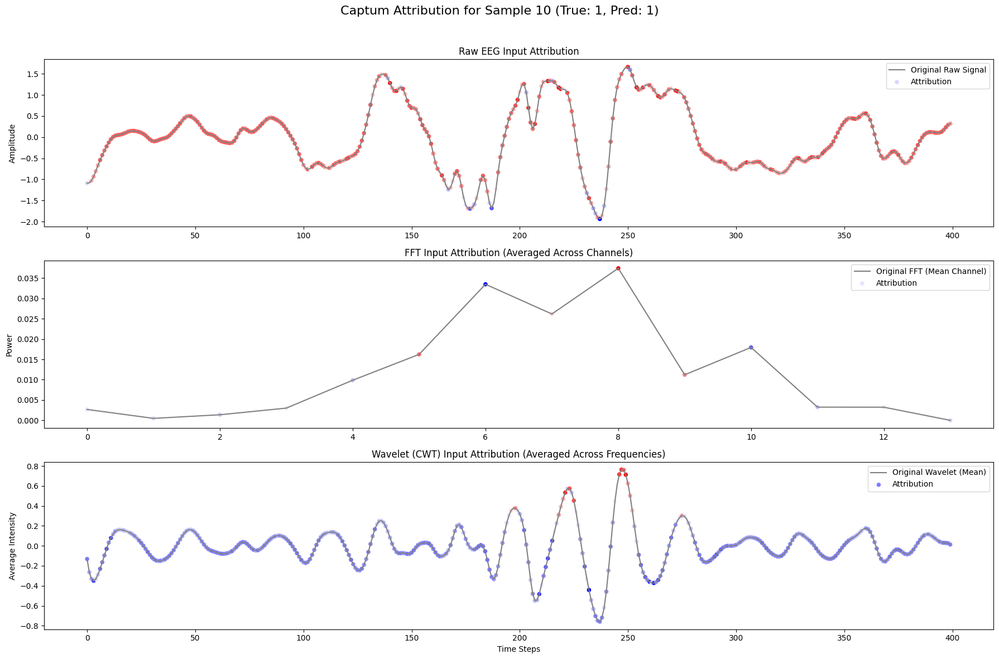


--- Analyzing Sample #3 (Index: 20) ---
True Label: 0 | Model Prediction: 1


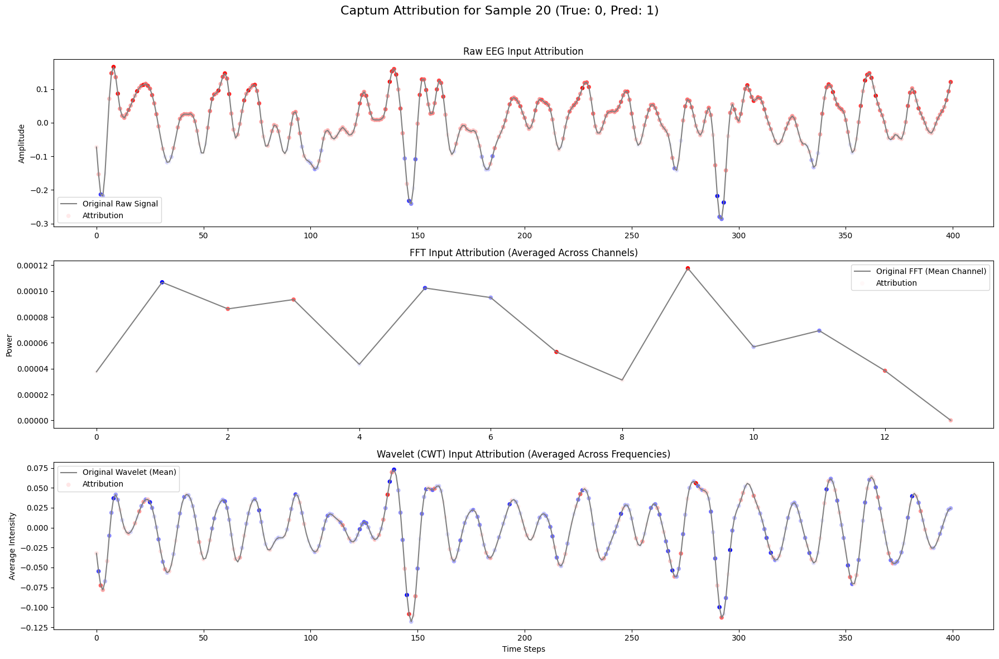


--- Analyzing Sample #4 (Index: 30) ---
True Label: 0 | Model Prediction: 1


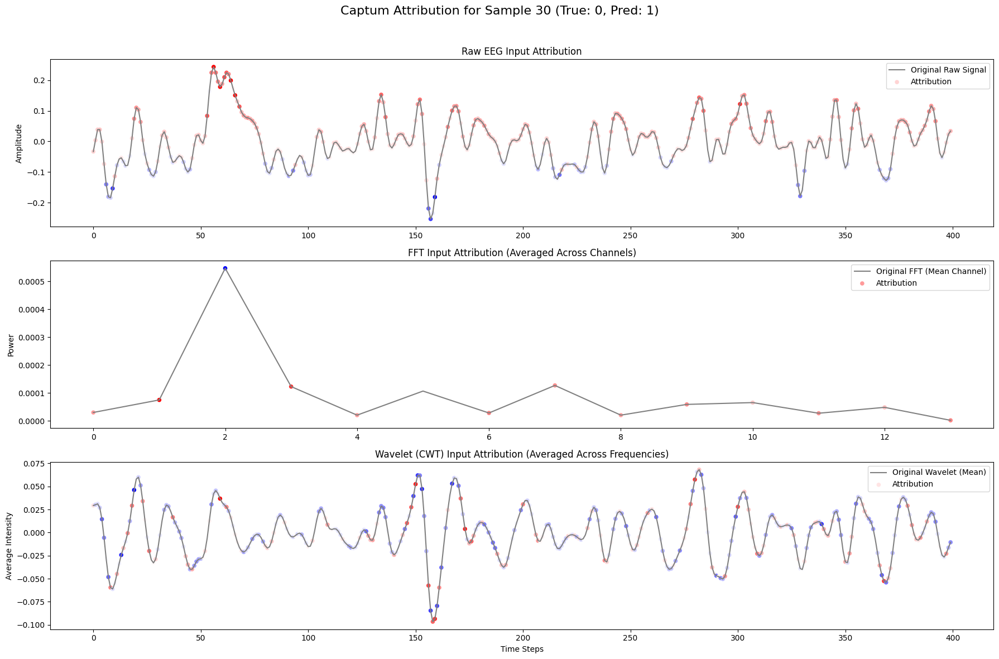

In [ ]:
# ====================================================================
# BLOCK 2: CAPTUM ANALYSIS FOR RAW + FFT + CWT MODEL
# ====================================================================
try:
    from captum.attr import IntegratedGradients

    # --- Step 1: Define the Wrapper Function for THREE inputs ---
    def model_wrapper(raw_input, fft_input, wavelet_input):
        """
        Wrapper for the model's forward pass. Captum passes the three tensors
        as separate arguments, which we format into a list for the model.
        """
        main_output, _ = model([raw_input, fft_input, wavelet_input], active_branch_indices=active_branches)
        return main_output

    # --- Step 2: Loop Through and Analyze 4 Samples ---
    sample_indices_to_analyze = [0, 10, 20, 30]
    print(f"\n--- Starting Captum Analysis for {len(sample_indices_to_analyze)} Samples ---")

    for i, sample_idx in enumerate(sample_indices_to_analyze):
        print(f"\n--- Analyzing Sample #{i+1} (Index: {sample_idx}) ---")
        
        _, raw_sample, fft_sample, wavelet_sample, label_sample = test_dataset[sample_idx]

        # Prepare 3D input tensors
        raw_input_3d = raw_sample.to(device)
        fft_input_3d = fft_sample.to(device)
        wavelet_input_3d = wavelet_sample.to(device)
        
        target_class = int(label_sample.item())
        
        # Get model's prediction
        model.eval()
        with torch.no_grad():
            output, _ = model([raw_input_3d, fft_input_3d, wavelet_input_3d], active_branch_indices=active_branches)
            prediction = torch.argmax(output, dim=1).item()
        print(f"True Label: {target_class} | Model Prediction: {prediction}")

        # Run Integrated Gradients
        ig = IntegratedGradients(model_wrapper)
        inputs_tuple = (raw_input_3d, fft_input_3d, wavelet_input_3d)
        baselines_tuple = (torch.zeros_like(raw_input_3d), torch.zeros_like(fft_input_3d), torch.zeros_like(wavelet_input_3d))
        attributions_tuple, delta = ig.attribute(inputs_tuple, baselines=baselines_tuple, target=target_class, return_convergence_delta=True)

        # --- Step 3: Visualize the Results for all THREE inputs ---
        raw_attr, fft_attr, wavelet_attr = attributions_tuple
        
        # Prepare data for plotting
        raw_attr_plot = raw_attr.squeeze().cpu().detach().numpy()
        raw_signal_plot = raw_input_3d.squeeze().cpu().detach().numpy()
        fft_attr_plot = fft_attr.squeeze().cpu().detach().numpy()
        fft_signal_plot = fft_input_3d.squeeze().cpu().detach().numpy()
        wavelet_attr_plot = wavelet_attr.squeeze().cpu().detach().numpy()
        wavelet_signal_plot = wavelet_input_3d.squeeze().cpu().detach().numpy()
        
        # Create a figure with three subplots
        fig, axs = plt.subplots(3, 1, figsize=(18, 12))
        fig.suptitle(f'Captum Attribution for Sample {sample_idx} (True: {target_class}, Pred: {prediction})', fontsize=16)

        # Plot Raw EEG Attribution
        time_steps_raw = np.arange(raw_signal_plot.shape[-1])
        norm_attr_raw = raw_attr_plot / np.linalg.norm(raw_attr_plot)
        axs[0].plot(time_steps_raw, raw_signal_plot, color='gray', label='Original Raw Signal')
        axs[0].scatter(time_steps_raw, raw_signal_plot, c=norm_attr_raw, cmap='bwr', s=20, label='Attribution')
        axs[0].set_title("Raw EEG Input Attribution")
        axs[0].set_ylabel('Amplitude')
        axs[0].legend()
        
        # Plot FFT Attribution (averaging channels)
        fft_signal_1d = fft_signal_plot.mean(axis=0) if fft_signal_plot.ndim > 1 else fft_signal_plot
        fft_attr_1d = fft_attr_plot.mean(axis=0) if fft_attr_plot.ndim > 1 else fft_attr_plot
        freq_bins = np.arange(fft_signal_1d.shape[-1])
        norm_attr_fft = fft_attr_1d / np.linalg.norm(fft_attr_1d)
        axs[1].plot(freq_bins, fft_signal_1d, color='gray', label='Original FFT (Mean Channel)')
        axs[1].scatter(freq_bins, fft_signal_1d, c=norm_attr_fft, cmap='bwr', s=20, label='Attribution')
        axs[1].set_title("FFT Input Attribution (Averaged Across Channels)")
        axs[1].set_ylabel('Power')
        axs[1].legend()

        # Plot Wavelet Attribution (averaging channels)
        wavelet_signal_1d = wavelet_signal_plot.mean(axis=0) if wavelet_signal_plot.ndim > 1 else wavelet_signal_plot
        wavelet_attr_1d = wavelet_attr_plot.mean(axis=0) if wavelet_attr_plot.ndim > 1 else wavelet_attr_plot
        time_steps_wavelet = np.arange(wavelet_signal_1d.shape[-1])
        norm_attr_wavelet = wavelet_attr_1d / np.linalg.norm(wavelet_attr_1d)
        axs[2].plot(time_steps_wavelet, wavelet_signal_1d, color='gray', label='Original Wavelet (Mean)')
        axs[2].scatter(time_steps_wavelet, wavelet_signal_1d, c=norm_attr_wavelet, cmap='bwr', s=20, label='Attribution')
        axs[2].set_title("Wavelet (CWT) Input Attribution (Averaged Across Frequencies)")
        axs[2].set_ylabel('Average Intensity')
        axs[2].set_xlabel('Time Steps')
        axs[2].legend()

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

except NameError as e:
     print(f"\nSkipping Captum analysis because a required variable was not found: {e}")
except Exception as e:
    print(f"\nAn error occurred during Captum analysis: {e}")